In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv(ruta_csv)
df.entidad_federativa.unique()



<StringArray>
[     'Aguascalientes',     'Baja California', 'Baja California Sur',
            'Campeche',            'Coahuila',              'Colima',
             'Chiapas',           'Chihuahua',    'Ciudad de México',
             'Durango',          'Guanajuato',            'Guerrero',
             'Hidalgo',             'Jalisco',    'Estado de México',
           'Michoacán',             'Morelos',             'Nayarit',
          'Nuevo León',              'Oaxaca',              'Puebla',
           'Querétaro',        'Quintana Roo',     'San Luis Potosí',
             'Sinaloa',              'Sonora',             'Tabasco',
          'Tamaulipas',            'Tlaxcala',            'Veracruz',
             'Yucatán',           'Zacatecas']
Length: 32, dtype: str

In [3]:
df["fecha"] = pd.to_datetime(df["fecha"], format="%Y-%m-%d", errors="coerce")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 413952 entries, 0 to 413951
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   anio                    413952 non-null  int64         
 1   clave_ent               413952 non-null  int64         
 2   entidad                 413952 non-null  str           
 3   bien_juridico_afectado  413952 non-null  str           
 4   tipo_delito             413952 non-null  str           
 5   subtipo_delito          413952 non-null  str           
 6   modalidad               413952 non-null  str           
 7   mes                     413952 non-null  str           
 8   fecha                   413952 non-null  datetime64[us]
 9   incidencia_delictiva    413952 non-null  int64         
 10  entidad_federativa      413952 non-null  str           
dtypes: datetime64[us](1), int64(3), str(7)
memory usage: 34.7 MB


In [4]:
# eliminar una fila de entidad por funcionalidad

df = df.copy()
df = df.drop(columns="entidad")

# Homicidios doloso en Jailsco por modalidad

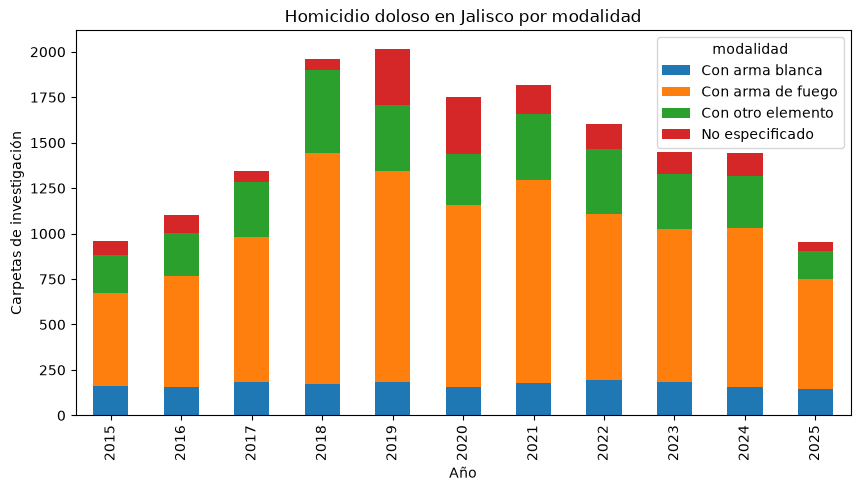

In [5]:
df_jalisco = df.loc[df["entidad_federativa"] == "Jalisco"]
df_jalisco = df_jalisco.loc[df_jalisco["tipo_delito"] == "Homicidio"]
df_jalisco = df_jalisco.loc[df_jalisco["subtipo_delito"] == "Homicidio doloso"]

anual = (df_jalisco.groupby([df_jalisco["fecha"].dt.year,"modalidad"])["incidencia_delictiva"].sum().unstack())


fig, ax = plt.subplots(figsize=(10, 5))
anual.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Homicidio doloso en Jalisco por modalidad")
ax.set_xlabel("Año")
ax.set_ylabel("Carpetas de investigación")
plt.show()



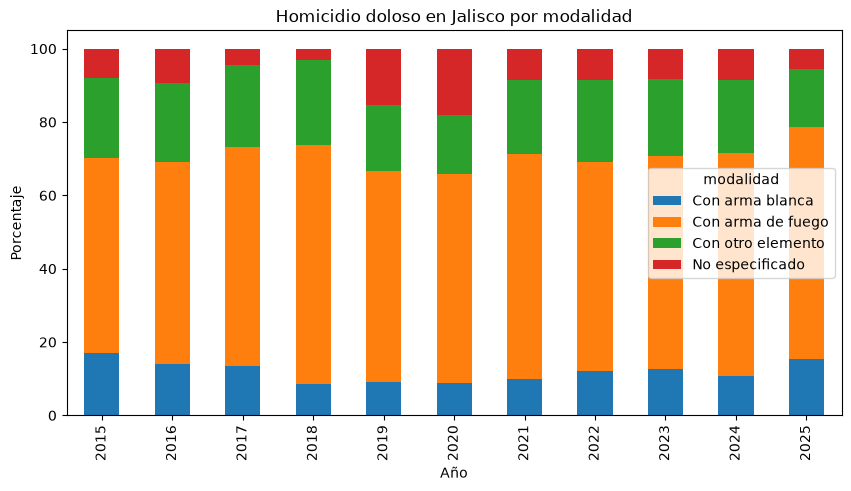

In [6]:
totales = anual.sum(axis=1)
prop = anual.div(totales, axis=0) * 100


fig, ax = plt.subplots(figsize=(10, 5))
prop.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Homicidio doloso en Jalisco por modalidad")
ax.set_xlabel("Año")
ax.set_ylabel("Porcentaje")
plt.show()

## Conclusión

Entre 2015 y 2025, la proporción de homicidios dolosos en Jalisco cometidos con
arma de fuego pasó de 53.4 % a 63.4 % (+10 puntos porcentuales). El aumento no
fue constante: alcanzó 64.9 % en 2018, bajó a 57.1 % en 2020 y se recuperó hasta
2025. En el mismo periodo, "con otro elemento" bajó de 21.7 % a 15.8 % y
"con arma blanca" de 16.9 % a 15.3 %.

La categoría "No especificado" pasó de 3.0 % en 2018 a 15.4 % en 2019 y 18.1 %
en 2020, su máximo en la serie, y volvió a 5.5 % en 2025. En esos años la caída
de arma de fuego y de otro elemento coincide con ese aumento, por lo que parte
del cambio puede deberse a casos sin clasificar y no a un cambio real en la
forma de los homicidios. Los resultados de 2019-2020 deben leerse con cautela.

**Limitaciones:** los datos son carpetas de investigación, no incluyen delitos
no denunciados. No hay comparación con otros estados ni con el total nacional,
así que no se puede afirmar si Jalisco sigue o se aparta de la tendencia del país.

**Posible explicación (no verificada con estos datos):** el aumento podría estar
relacionado con la disponibilidad de armas de fuego, pero este análisis no mide
esa relación.

# ¿Cómo cambió el homicidio doloso durante la pandemia (2020) comparado al año 2019? ¿Fue igual en todos los estados?

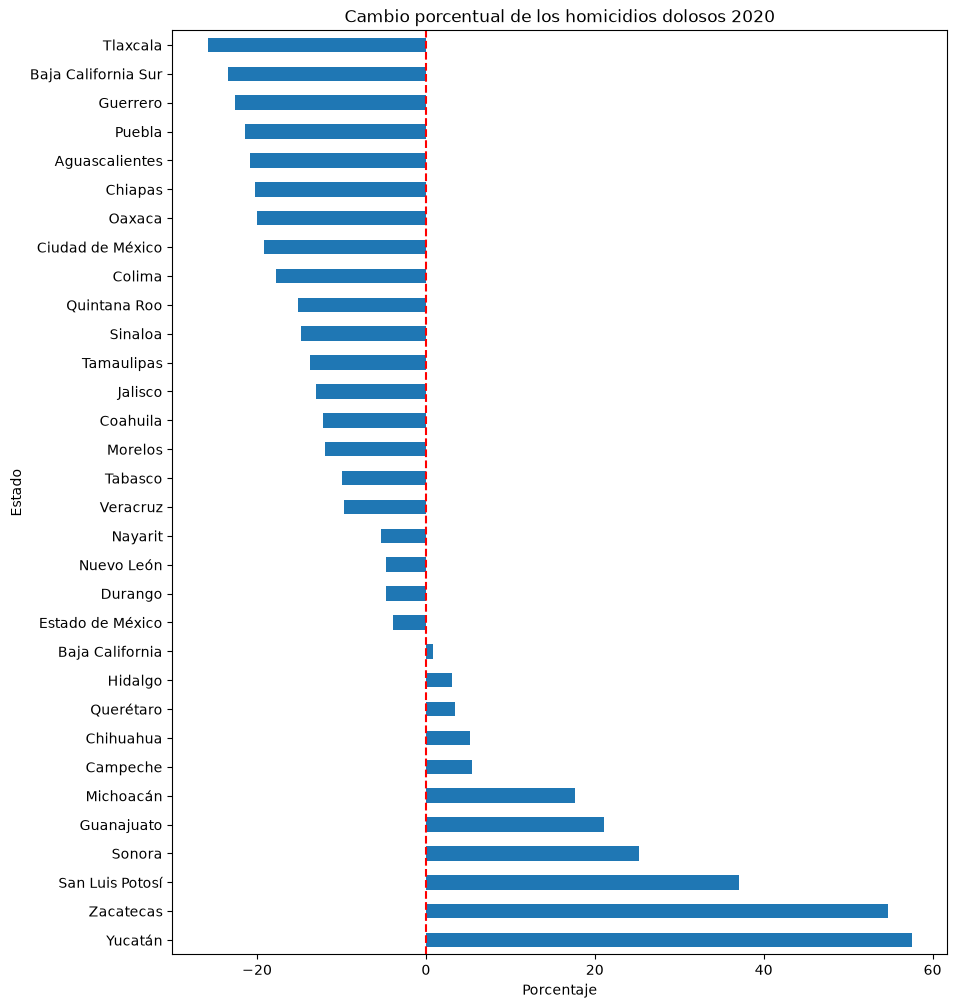

In [ ]:
df_homicido = df.loc[df["subtipo_delito"] == "Homicidio doloso"]
df_homicido = df_homicido[(df_homicido["anio"] <= 2021)]

df_homicido = df_homicido.groupby([df_homicido["fecha"].dt.year,"entidad_federativa"])["incidencia_delictiva"].sum().unstack()
df_homicido = df_homicido.pct_change() * 100
df_homicidio = df_homicido.round(2)

df_homicidio_2020 = df_homicidio.iloc[5,:]
df_homicidio_2020 = df_homicidio_2020.sort_values(ascending=False)


fig,ax = plt.subplots(figsize=(10,12))
df_homicidio_2020.plot(kind="barh",ax=ax)
ax.set_title("Cambio porcentual de los homicidios dolosos 2020")
ax.set_ylabel("Estado")
ax.set_xlabel("Porcentaje")
ax.axvline(x=0, color="red", linestyle="--")
plt.show()



fecha
2015    16119
2016    20147
2017    25032
2018    29092
2019    29498
2020    28839
2021    28279
Name: incidencia_delictiva, dtype: int64


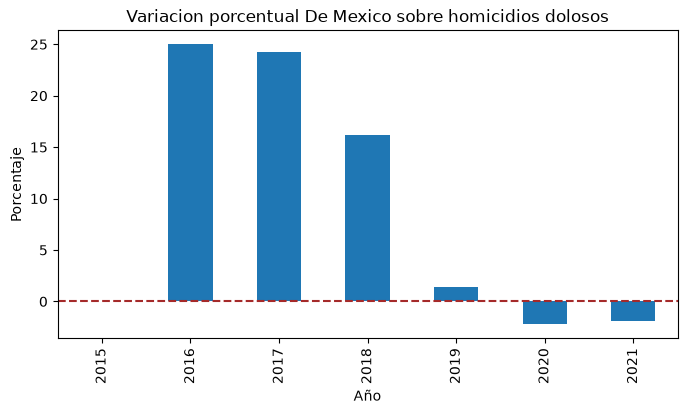

In [35]:
cambio_nacional =df.loc[df["subtipo_delito"] == "Homicidio doloso"]
cambio_nacional = cambio_nacional[(cambio_nacional["anio"] <= 2021)]
cambio_nacional = cambio_nacional.groupby(cambio_nacional["fecha"].dt.year)["incidencia_delictiva"].sum()

print(cambio_nacional) 

cambio_nacional = (cambio_nacional.pct_change()*100).round(2)
fig,ax = plt.subplots(figsize=(8,4))
cambio_nacional.plot(kind="bar",ax=ax)
ax.set_title("Variacion porcentual De Mexico sobre homicidios dolosos")
ax.set_ylabel("Porcentaje")
ax.set_xlabel("Año")
ax.axhline( y=0, color="brown",linestyle="--")
plt.show() 




# Conclusión
Entre 2019 y 2020, el homicidio doloso (carpetas de investigación) a nivel nacional pasó de 29,498 a 28,839, una baja de 2.2%. Es el primer año con descenso en la serie 2015-2021, pero la magnitud es pequeña y similar a la de 2021 (−1.9%). El total nacional venía creciendo con fuerza hasta 2018 (+25.0% en 2016, +24.2% en 2017, +16.2% en 2018), ya se había estancado en 2019 (+1.4%) y en 2021 se mantuvo ligeramente por debajo del nivel de 2019 (−4.1%). Los datos muestran el fin de una tendencia al alza, no una caída abrupta en 2020.

Por estado, la variación fue muy desigual. 21 de las 32 entidades registraron una baja en 2020 y 11 una alza, con cambios que van aproximadamente de −26% (Tlaxcala) a +58% (Yucatán). Entre las mayores caídas porcentuales están Tlaxcala, Baja California Sur, Guerrero, Puebla y Aguascalientes; entre los mayores aumentos, Yucatán, Zacatecas, San Luis Potosí, Sonora y Guanajuato. Que la mayoría de los estados haya bajado y el total nacional solo −2.2% sugiere que los estados con aumentos tienen un peso considerable en el total.

Estos datos describen qué cambió, no por qué. No permiten atribuir las variaciones a la pandemia: la ventana de comparación es corta y el cambio nacional de 2020 no es muy distinto al de 2021.

Limitaciones:

Se miden carpetas de investigación, no víctimas ni delitos no denunciados.
Los cambios porcentuales por estado no consideran el tamaño del estado. En entidades con pocos casos, un cambio pequeño en número produce un porcentaje grande, por lo que los extremos deben leerse con cautela.
No se calculó el cambio absoluto por estado, así que no se puede afirmar qué entidades explican la variación nacional.
No hay ajuste por población.
Los fuertes aumentos de 2016 y 2017 no se interpretaron, porque no se verificó si la serie es comparable con la de años posteriores (posibles cambios en la metodología de registro).